# Part A – Data Preparation and Exploratory Analysis

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB
None
Missing values:
 fixed acidity           0
volatile acidit

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


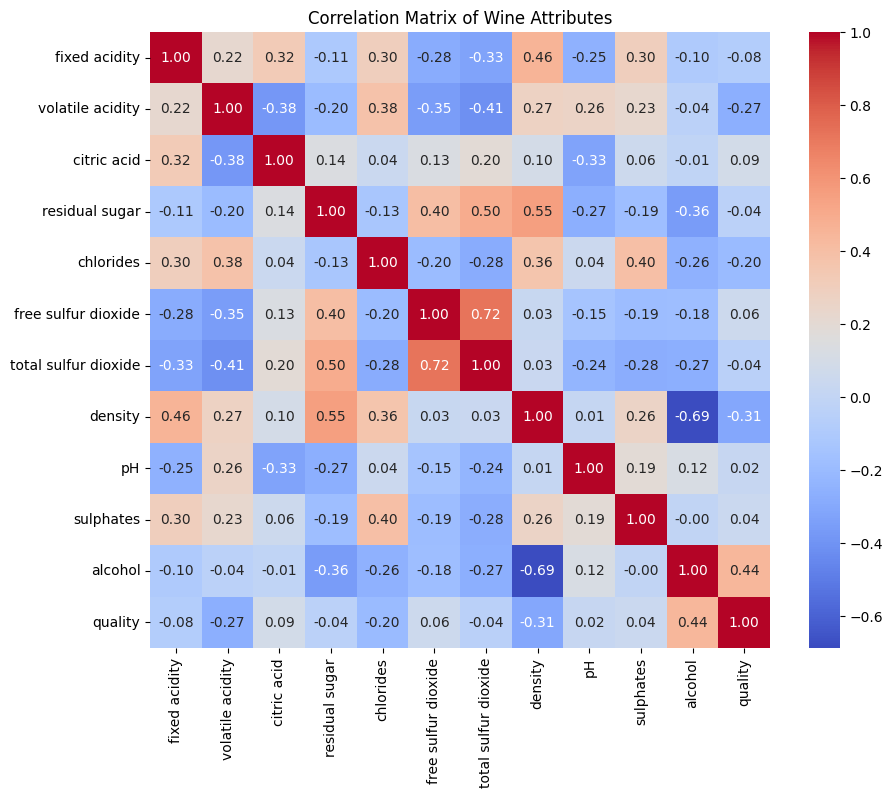

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Import datasets
red_wine = pd.read_csv('winequality-red.csv', sep=';')
white_wine = pd.read_csv('winequality-white.csv', sep=';')

# 2 & 3. Add color variable and combine
red_wine['color'] = 'Red'
white_wine['color'] = 'White'
wine_data = pd.concat([red_wine, white_wine], ignore_index=True)

# 4 - 8. Examine structure, missing values, duplicates, and outliers
print(wine_data.info())
print("Missing values:\n", wine_data.isnull().sum())
print("Duplicates:", wine_data.duplicated().sum())

# 9 - 12. Descriptive statistics and visualizations
display(wine_data.describe())

# Example Visualization: Correlation Heatmap
plt.figure(figsize=(10, 8))
# Drop categorical 'color' for correlation
numeric_cols = wine_data.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Wine Attributes")
plt.show()

# Part B – Multivariate Analysis of Variance (MANOVA)

In [6]:
from statsmodels.multivariate.manova import MANOVA

# Replace spaces with underscores in all column names to work with statsmodels formulas
wine_data.columns = wine_data.columns.str.replace(' ', '_')

# 1. State Hypotheses
print("Hypotheses for MANOVA:")
print("H0: The mean vector of the selected physicochemical variables is the same for red and white wines.") #[cite: 5]
print("H1: The mean vectors differ between red and white wines.\n") #[cite: 5]

# 3. Conduct MANOVA (using the newly underscored column names)
manova = MANOVA.from_formula('fixed_acidity + volatile_acidity + citric_acid + residual_sugar ~ color', data=wine_data)
print("MANOVA Results:")
print(manova.mv_test())

Hypotheses for MANOVA:
H0: The mean vector of the selected physicochemical variables is the same for red and white wines.
H1: The mean vectors differ between red and white wines.

MANOVA Results:
                    Multivariate linear model
                                                                  
------------------------------------------------------------------
       Intercept         Value  Num DF   Den DF   F Value   Pr > F
------------------------------------------------------------------
          Wilks' lambda  0.0466 4.0000 6492.0000 33214.4093 0.0000
         Pillai's trace  0.9534 4.0000 6492.0000 33214.4093 0.0000
 Hotelling-Lawley trace 20.4648 4.0000 6492.0000 33214.4093 0.0000
    Roy's greatest root 20.4648 4.0000 6492.0000 33214.4093 0.0000
------------------------------------------------------------------
                                                                  
------------------------------------------------------------------
           color     

# Part C – Principal Component Analysis (PCA)

Eigenvalues (Variance explained by each component):
[3.03033507 2.49420993 1.55658654 0.97070149 0.71998573 0.6074052
 0.5232393  0.50158749 0.33707593 0.22773082 0.03283586]

Proportion of Variance Explained:
[0.2754426  0.22671146 0.14148609 0.08823201 0.06544317 0.05521016
 0.04755989 0.04559184 0.03063855 0.02069961 0.00298462]

Cumulative Variance Explained:
[0.2754426  0.50215406 0.64364015 0.73187216 0.79731533 0.85252548
 0.90008537 0.94567722 0.97631577 0.99701538 1.        ]


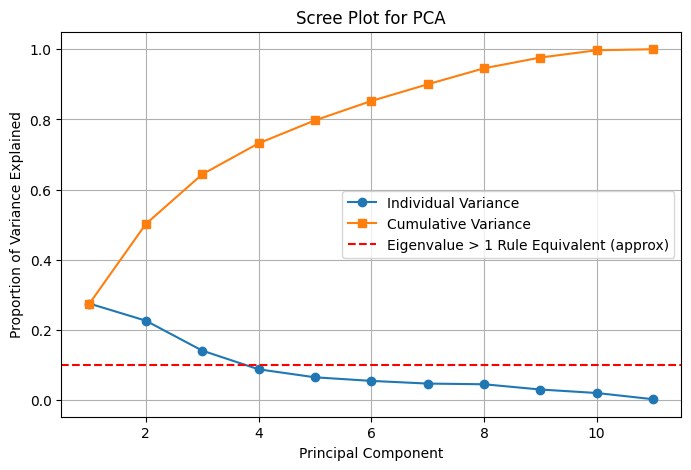


Component Loadings (First 3 Components):


,PC1,PC2,PC3
fixed_acidity,-0.238799,0.336355,0.434301
volatile_acidity,-0.380757,0.117550,-0.307259
citric_acid,0.152388,0.183299,0.590570
residual_sugar,0.345920,0.329914,-0.164688
chlorides,-0.290113,0.315258,-0.016679
free_sulfur_dioxide,0.430914,0.071933,-0.134224
total_sulfur_dioxide,0.487418,0.087266,-0.107462
density,-0.044937,0.584037,-0.175606
pH,-0.218686,-0.155869,-0.455324
sulphates,-0.294135,0.191716,0.070042


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Updated features list using underscores instead of spaces
pca_features = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
                'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
                'pH', 'sulphates', 'alcohol']

# 1. Examine correlation structure (handled in EDA/Report)
X = wine_data[pca_features]

# 2. Standardize the variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3 & 4. Determine components and report results
pca = PCA()
pca.fit(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Eigenvalues (Variance explained by each component):")
print(pca.explained_variance_)
print("\nProportion of Variance Explained:")
print(explained_variance)
print("\nCumulative Variance Explained:")
print(cumulative_variance)

# 5. Visualize PCA (Scree Plot)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', label='Individual Variance')
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='s', label='Cumulative Variance')
plt.axhline(y=0.1, color='r', linestyle='--', label='Eigenvalue > 1 Rule Equivalent (approx)')
plt.xlabel('Principal Component')
plt.ylabel('Proportion of Variance Explained')
plt.title('Scree Plot for PCA')
plt.legend()
plt.grid(True)
plt.show()

# 6. Component Loadings (to interpret components in your report)
loadings = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(len(pca_features))], index=pca_features)
print("\nComponent Loadings (First 3 Components):")
display(loadings[['PC1', 'PC2', 'PC3']])

# Part D – Exploratory Factor Analysis (EFA)

In [10]:
!pip install factor_analyzer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.8/42.8 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42655 sha256=b4e78a263bc0af34fd149add51f32b4140f3fbcc2f1f2254d32d1ccb3b8e44ca
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [11]:
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

# 1. Assess factorability
chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled)
kmo_all, kmo_model = calculate_kmo(X_scaled)

print(f"Bartlett's Test p-value: {p_value}")
print(f"KMO Measure: {kmo_model}")

# 3 & 4. Select extraction and rotation method
# Example: varimax (orthogonal) or promax (oblique). Justify your choice.
fa = FactorAnalyzer(n_factors=3, rotation='promax')
fa.fit(X_scaled)

# 5. Examine factor loadings
loadings = fa.loadings_
communalities = fa.get_communalities()

Bartlett's Test p-value: 0.0
KMO Measure: 0.4052524118323978


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
